In [1]:
# from google.colab import drive
# drive.mount('/content/drive')

In [2]:
import pandas as pd
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
filepath = {
    'Source-1': 'sentiment-data/one.txt',
    'Source-2': 'sentiment-data/two.txt',
    'Source-3': 'sentiment-data/three.txt'}
df_list = []
for source, path in filepath.items():
    df = pd.read_csv(path, names=['text', 'label'], sep='\t')
    df_list.append(df)
df = pd.concat(df_list)
print("Dataset read successfully")

Dataset read successfully


In [3]:
df.head()

,text,label
0,So there is no way for me to plug it in here i...,0
1,"Good case, Excellent value.",1
2,Great for the jawbone.,1
3,Tied to charger for conversations lasting more...,0
4,The mic is great.,1


In [4]:
print(len(df))

2748


In [5]:
df.head()

,text,label
0,So there is no way for me to plug it in here i...,0
1,"Good case, Excellent value.",1
2,Great for the jawbone.,1
3,Tied to charger for conversations lasting more...,0
4,The mic is great.,1


In [6]:
from sklearn.model_selection import train_test_split
sentences = df['text'].values
y = df['label'].values
sentences_train, sentences_test, y_train, y_test = train_test_split(sentences, y, test_size=0.1, random_state=42)

In [7]:
print("sentences_train", len(sentences_train))
print("sentences_test", len(sentences_test))
print("y_train", len(y_train))
print("y_test", len(y_test))
#print(sentences_test)

sentences_train 2473
sentences_test 275
y_train 2473
y_test 275


In [14]:
from sklearn.feature_extraction.text import CountVectorizer
vectorizer = CountVectorizer()
vectorizer.fit(sentences_train)
X_train = vectorizer.transform(sentences_train)
X_test  = vectorizer.transform(sentences_test)

In [15]:
X_test

<Compressed Sparse Row sparse matrix of dtype 'int64'
	with 2606 stored elements and shape (275, 4888)>

In [16]:
X_train.shape

(2473, 4888)

# Evaluating for each data source

In [17]:
from keras.models import Sequential
from keras import layers
input_dim = X_train.shape[1]  # Number of features
model = Sequential()
model.add(layers.Dense(100, input_dim=input_dim, activation='relu'))
model.add(layers.Dense(10, input_dim=100, activation='relu'))
model.add(layers.Dense(1, activation='sigmoid'))

C:\Users\Hp\anaconda3\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [18]:
model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 100)            │       488,900 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,010 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            11 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 489,921 (1.87 MB)

 Trainable params: 489,921 (1.87 MB)

 Non-trainable params: 0 (0.00 B)

In [19]:
model.fit(X_train, y_train, epochs=100, validation_data=(X_test, y_test), batch_size=100)

Epoch 1/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 2s 26ms/step - accuracy: 0.6175 - loss: 0.6826 - val_accuracy: 0.7309 - val_loss: 0.6675
Epoch 2/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.8795 - loss: 0.5909 - val_accuracy: 0.7309 - val_loss: 0.5932
Epoch 3/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.9106 - loss: 0.4201 - val_accuracy: 0.8182 - val_loss: 0.4760
Epoch 4/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.9539 - loss: 0.2540 - val_accuracy: 0.8218 - val_loss: 0.4192
Epoch 5/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.9717 - loss: 0.1591 - val_accuracy: 0.8291 - val_loss: 0.4164
Epoch 6/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.9798 - loss: 0.1265 - val_accuracy: 0.8218 - val_loss: 0.4357
Epoch 7/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.9814 - loss: 0.1004 - val_accuracy: 0.7964 - val_loss: 0.4803
Epoch 8/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.9907 - loss: 0.0645 - val_accuracy: 0.

In [20]:
history = model.fit(X_train, y_train, epochs=50, verbose=False, validation_data=(X_test, y_test), batch_size=100)
#history = model.fit(X_train, y_train, epochs=1000, verbose=False, validation_data=(X_test, y_test), batch_size=100)

In [21]:
loss, accuracy = model.evaluate(X_train, y_train, verbose=False)
print("Training Accuracy: {:.4f}".format(accuracy))
loss, accuracy = model.evaluate(X_test, y_test, verbose=False)
print("Testing Accuracy:  {:.4f}".format(accuracy))

Training Accuracy: 1.0000
Testing Accuracy:  0.8291


In [22]:
print(history.history['accuracy'])

[1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]


In [23]:
print(history.history['val_accuracy'])

[0.8254545331001282, 0.8254545331001282, 0.8254545331001282, 0.8254545331001282, 0.8254545331001282, 0.8254545331001282, 0.8254545331001282, 0.8254545331001282, 0.8254545331001282, 0.8254545331001282, 0.8254545331001282, 0.8254545331001282, 0.8254545331001282, 0.8254545331001282, 0.8254545331001282, 0.8254545331001282, 0.8254545331001282, 0.8254545331001282, 0.8254545331001282, 0.8254545331001282, 0.8254545331001282, 0.8254545331001282, 0.8254545331001282, 0.8254545331001282, 0.8254545331001282, 0.8254545331001282, 0.8254545331001282, 0.8290908932685852, 0.8254545331001282, 0.8290908932685852, 0.8290908932685852, 0.8290908932685852, 0.8290908932685852, 0.8290908932685852, 0.8290908932685852, 0.8290908932685852, 0.8290908932685852, 0.8290908932685852, 0.8290908932685852, 0.8290908932685852, 0.8290908932685852, 0.8290908932685852, 0.8290908932685852, 0.8290908932685852, 0.8290908932685852, 0.8290908932685852, 0.8290908932685852, 0.8290908932685852, 0.8290908932685852, 0.8290908932685852]

In [24]:
print(history.history['loss'])

[0.00012176909513073042, 0.0001184879511129111, 0.00011538561375346035, 0.00011218963481951505, 0.0001093757527996786, 0.00010655685036908835, 0.00010374288103776053, 0.00010122425737790763, 9.8700329544954e-05, 9.626626706449315e-05, 9.380200935993344e-05, 9.160960325971246e-05, 8.927189628593624e-05, 8.712889393791556e-05, 8.489011088386178e-05, 8.292465645354241e-05, 8.095190423773602e-05, 7.90388003224507e-05, 7.721698784735054e-05, 7.544230174971744e-05, 7.361606549238786e-05, 7.184686546679586e-05, 7.027632091194391e-05, 6.863594171591103e-05, 6.714190385537222e-05, 6.56285192235373e-05, 6.40703656245023e-05, 6.272265454754233e-05, 6.128225504653528e-05, 5.993293598294258e-05, 5.8611327403923497e-05, 5.7357287005288526e-05, 5.6042779760900885e-05, 5.488589886226691e-05, 5.371734732761979e-05, 5.2544597565429285e-05, 5.1402475946815684e-05, 5.027358201914467e-05, 4.918540071230382e-05, 4.812623592442833e-05, 4.7087269194889814e-05, 4.61573654320091e-05, 4.517450724961236e-05, 4.42

In [25]:
print(history.history['val_loss'])

[0.9110800623893738, 0.9142376184463501, 0.9169812202453613, 0.9197151064872742, 0.9227049946784973, 0.9255480766296387, 0.927805483341217, 0.930660605430603, 0.9333023428916931, 0.9360145330429077, 0.9384102821350098, 0.9408627152442932, 0.943913996219635, 0.9461570978164673, 0.9491348266601562, 0.9515058994293213, 0.9545379281044006, 0.9571003913879395, 0.9593220949172974, 0.9615944623947144, 0.9643359184265137, 0.9665327668190002, 0.9690953493118286, 0.9715549349784851, 0.9736847281455994, 0.9762619733810425, 0.9792478084564209, 0.9810328483581543, 0.9839370846748352, 0.9860000610351562, 0.9881376624107361, 0.9907426238059998, 0.9928353428840637, 0.9949907064437866, 0.9973917007446289, 0.9994431138038635, 1.00227689743042, 1.0043118000030518, 1.0067147016525269, 1.008416771888733, 1.0107723474502563, 1.0130460262298584, 1.01541006565094, 1.0175410509109497, 1.0193305015563965, 1.0218048095703125, 1.0239008665084839, 1.026097297668457, 1.0280826091766357, 1.030603051185608]


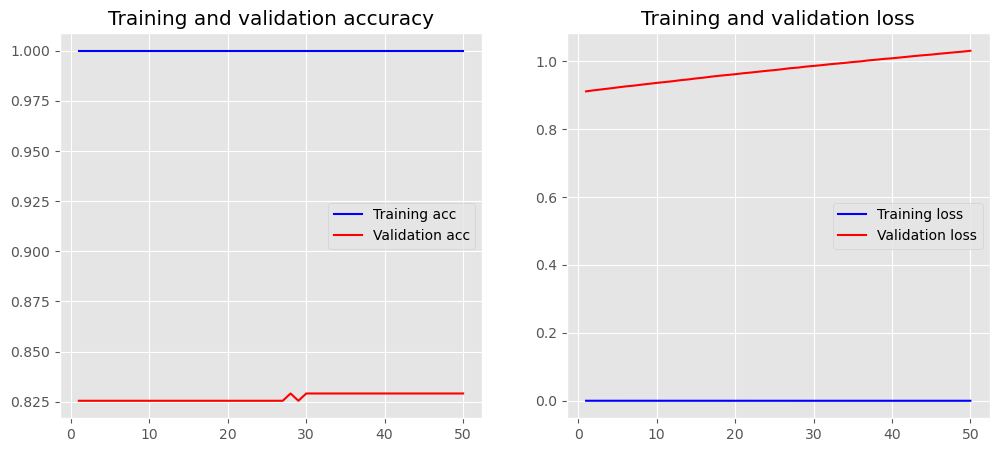

In [26]:
import matplotlib.pyplot as plt
plt.style.use('ggplot')
def plot_history(history):
    acc = history.history['accuracy']
    val_acc = history.history['val_accuracy']
    loss = history.history['loss']
    val_loss = history.history['val_loss']
    x = range(1, len(acc) + 1)
    plt.figure(figsize=(12, 5))
    plt.subplot(1, 2, 1)
    plt.plot(x, acc, 'b', label='Training acc')
    plt.plot(x, val_acc, 'r', label='Validation acc')
    plt.title('Training and validation accuracy')
    plt.legend()
    plt.subplot(1, 2, 2)
    plt.plot(x, loss, 'b', label='Training loss')
    plt.plot(x, val_loss, 'r', label='Validation loss')
    plt.title('Training and validation loss')
    plt.legend()
plot_history(history)

In [27]:
# Try to have an optimaized result without shuffling it by manuiplating the parameter, apply embbedding in this daset and train it, 
# use word2vec

In [28]:
# 1. Simplified architecture with high regularization
model = Sequential([
    Dense(32, activation='relu', kernel_regularizer=tf.keras.regularizers.l2(0.01), input_shape=(X_train.shape[1],)),
    Dropout(0.6), # Aggressive dropout
    Dense(16, activation='relu', kernel_regularizer=tf.keras.regularizers.l2(0.01)),
    Dropout(0.5),
    Dense(1, activation='sigmoid')
])

# Lower learning rate
optimizer = tf.keras.optimizers.Adam(learning_rate=0.0005)
model.compile(optimizer=optimizer, loss='binary_crossentropy', metrics=['accuracy'])

# Early stopping to halt training once validation loss climbs
early_stop = EarlyStopping(monitor='val_loss', patience=4, restore_best_weights=True)

# Massive batch size and NO shuffling
history = model.fit(
    X_train, y_train,
    epochs=50, 
    batch_size=1024, # Drastically increased to counter unshuffled data
    validation_data=(X_train, y_train),
    shuffle=False,   # Explicitly disabled
    callbacks=[early_stop]
)

C:\Users\Hp\anaconda3\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/50
3/3 ━━━━━━━━━━━━━━━━━━━━ 4s 488ms/step - accuracy: 0.5059 - loss: 1.5253 - val_accuracy: 0.4893 - val_loss: 1.4673
Epoch 2/50
3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 240ms/step - accuracy: 0.5034 - loss: 1.4487 - val_accuracy: 0.5002 - val_loss: 1.3958
Epoch 3/50
3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 255ms/step - accuracy: 0.5071 - loss: 1.3798 - val_accuracy: 0.5168 - val_loss: 1.3308
Epoch 4/50
3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 225ms/step - accuracy: 0.5119 - loss: 1.3154 - val_accuracy: 0.5487 - val_loss: 1.2719
Epoch 5/50
3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 205ms/step - accuracy: 0.5091 - loss: 1.2581 - val_accuracy: 0.5722 - val_loss: 1.2188
Epoch 6/50
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 151ms/step - accuracy: 0.5334 - loss: 1.2064 - val_accuracy: 0.5964 - val_loss: 1.1713
Epoch 7/50
3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 216ms/step - accuracy: 0.5443 - loss: 1.1599 - val_accuracy: 0.6183 - val_loss: 1.1289
Epoch 8/50
3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 198ms/step - accuracy: 0.5451 - loss: 1.1199 - val_accuracy: 0.6470 - val_loss:

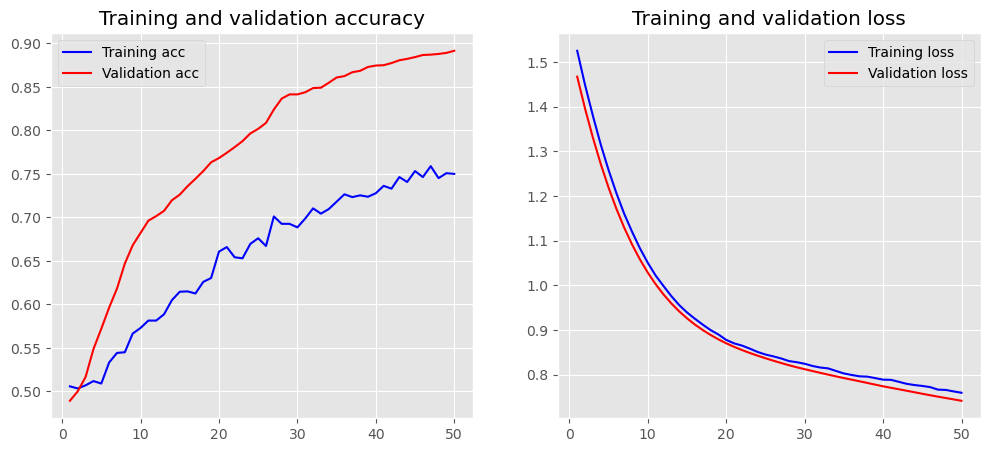

In [29]:
import matplotlib.pyplot as plt
plt.style.use('ggplot')

def plot_history(history):
    # Extract accuracy and loss from the new history object
    acc = history.history['accuracy']
    val_acc = history.history['val_accuracy']
    loss = history.history['loss']
    val_loss = history.history['val_loss']
    
    # Define the x-axis based on the number of epochs the model actually ran
    x = range(1, len(acc) + 1)

    plt.figure(figsize=(12, 5))
    
    # Plot Accuracy
    plt.subplot(1, 2, 1)
    plt.plot(x, acc, 'b', label='Training acc')
    plt.plot(x, val_acc, 'r', label='Validation acc')
    plt.title('Training and validation accuracy')
    plt.legend()
    
    # Plot Loss
    plt.subplot(1, 2, 2)
    plt.plot(x, loss, 'b', label='Training loss')
    plt.plot(x, val_loss, 'r', label='Validation loss')
    plt.title('Training and validation loss')
    plt.legend()
    
    plt.show()

# Call the function to display the new graphs
plot_history(history)

In [30]:
# Re-process the Text Data
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# 1. Define vocabulary size and max sentence length
vocab_size = 10000  # Only keep the top 10,000 most frequent words
max_length = 50    # Pad/truncate all sentences to 50 words

# 2. Initialize and fit the Tokenizer
tokenizer = Tokenizer(num_words=vocab_size, oov_token="<OOV>")
tokenizer.fit_on_texts(sentences_train)

# 3. Convert text to integer sequences
train_sequences = tokenizer.texts_to_sequences(sentences_train)
test_sequences = tokenizer.texts_to_sequences(sentences_test) # Change to sentences_val if needed

# 4. Pad the sequences so they are uniform in length
X_train_pad = pad_sequences(train_sequences, maxlen=max_length, padding='post', truncating='post')
X_test_pad = pad_sequences(test_sequences, maxlen=max_length, padding='post', truncating='post')

print("New padded training shape:", X_train_pad.shape)

New padded training shape: (2473, 50)


In [31]:
# Build the Embedding Model
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Embedding, GlobalAveragePooling1D
import tensorflow as tf

embedding_dim = 50 # Size of the word vectors (higher = more detail, but slower)

model_emb = Sequential([
    # The Embedding layer (Learns word relationships)
    Embedding(input_dim=vocab_size, output_dim=embedding_dim, input_length=max_length),
    
    # Flatten the sequence of embeddings into a single 1D vector
    GlobalAveragePooling1D(),
    
    # Fully connected classifier
    Dense(32, activation='relu', kernel_regularizer=tf.keras.regularizers.l2(0.01)),
    Dropout(0.5),
    Dense(16, activation='relu', kernel_regularizer=tf.keras.regularizers.l2(0.01)),
    Dropout(0.5),
    Dense(1, activation='sigmoid')
])

# We can afford a slightly higher learning rate now
optimizer = tf.keras.optimizers.Adam(learning_rate=0.001) 
model_emb.compile(optimizer=optimizer, loss='binary_crossentropy', metrics=['accuracy'])

C:\Users\Hp\anaconda3\Lib\site-packages\keras\src\layers\core\embedding.py:123: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


In [32]:
# Train the Model
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(monitor='val_loss', patience=4, restore_best_weights=True)

history_emb = model_emb.fit(
    X_train_pad, y_train,
    epochs=100, 
    batch_size=256,   # Increased batch size to help with shuffle=False
    validation_data=(X_test_pad, y_test), 
    shuffle=False,    # Kept disabled per your instructions
    callbacks=[early_stop]
)

Epoch 1/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 4s 87ms/step - accuracy: 0.4873 - loss: 1.2615 - val_accuracy: 0.5600 - val_loss: 1.2275
Epoch 2/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - accuracy: 0.5083 - loss: 1.2038 - val_accuracy: 0.4473 - val_loss: 1.1744
Epoch 3/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - accuracy: 0.5135 - loss: 1.1518 - val_accuracy: 0.4473 - val_loss: 1.1262
Epoch 4/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 47ms/step - accuracy: 0.5196 - loss: 1.1046 - val_accuracy: 0.4473 - val_loss: 1.0816
Epoch 5/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step - accuracy: 0.5176 - loss: 1.0616 - val_accuracy: 0.4473 - val_loss: 1.0405
Epoch 6/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - accuracy: 0.5087 - loss: 1.0222 - val_accuracy: 0.4473 - val_loss: 1.0053
Epoch 7/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.5241 - loss: 0.9878 - val_accuracy: 0.4473 - val_loss: 0.9727
Epoch 8/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.5140 - loss: 0.9573 - val_accuracy: 0.

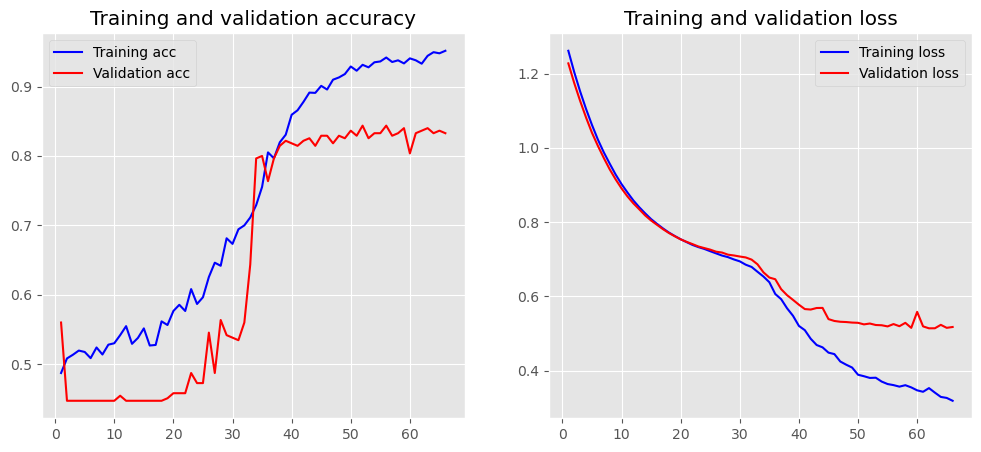

In [33]:
plot_history(history_emb)

In [34]:
# Rebuild the model with relaxed regularization
model_emb = Sequential([
    Embedding(input_dim=vocab_size, output_dim=embedding_dim, input_length=max_length),
    GlobalAveragePooling1D(),
    
    # Removed L2 regularization and lowered dropout to 0.2
    Dense(32, activation='relu'),
    Dropout(0.2), 
    Dense(16, activation='relu'),
    Dropout(0.2),
    Dense(1, activation='sigmoid')
])

# Compile and train again
optimizer = tf.keras.optimizers.Adam(learning_rate=0.001) 
model_emb.compile(optimizer=optimizer, loss='binary_crossentropy', metrics=['accuracy'])

# Run the fit function again...

In [35]:
from tensorflow.keras.callbacks import EarlyStopping

# Rebuild without the deprecated 'input_length' argument
model_emb = Sequential([
    Embedding(input_dim=vocab_size, output_dim=embedding_dim), # Warning fixed here
    GlobalAveragePooling1D(),
    Dense(32, activation='relu'),
    Dropout(0.2),
    Dense(16, activation='relu'),
    Dropout(0.2),
    Dense(1, activation='sigmoid')
])

# Compile
optimizer = tf.keras.optimizers.Adam(learning_rate=0.001) 
model_emb.compile(optimizer=optimizer, loss='binary_crossentropy', metrics=['accuracy'])

# Train the model (The actual "fit" step)
early_stop = EarlyStopping(monitor='val_loss', patience=4, restore_best_weights=True)

history_emb2 = model_emb.fit(
    X_train_pad, y_train,   # Using the padded data from the Tokenizer step
    epochs=50, 
    batch_size=256, 
    validation_data=(X_test_pad, y_test), 
    shuffle=False, 
    callbacks=[early_stop]
)

Epoch 1/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 4s 72ms/step - accuracy: 0.5002 - loss: 0.6938 - val_accuracy: 0.4473 - val_loss: 0.6936
Epoch 2/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.5107 - loss: 0.6925 - val_accuracy: 0.4473 - val_loss: 0.6959
Epoch 3/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.5233 - loss: 0.6909 - val_accuracy: 0.4473 - val_loss: 0.6945
Epoch 4/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.5249 - loss: 0.6910 - val_accuracy: 0.4473 - val_loss: 0.6947
Epoch 5/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.5503 - loss: 0.6874 - val_accuracy: 0.4582 - val_loss: 0.6924
Epoch 6/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - accuracy: 0.6009 - loss: 0.6845 - val_accuracy: 0.4618 - val_loss: 0.6914
Epoch 7/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.6276 - loss: 0.6790 - val_accuracy: 0.4764 - val_loss: 0.6859
Epoch 8/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 0.6332 - loss: 0.6721 - val_accuracy: 0.5018 - v

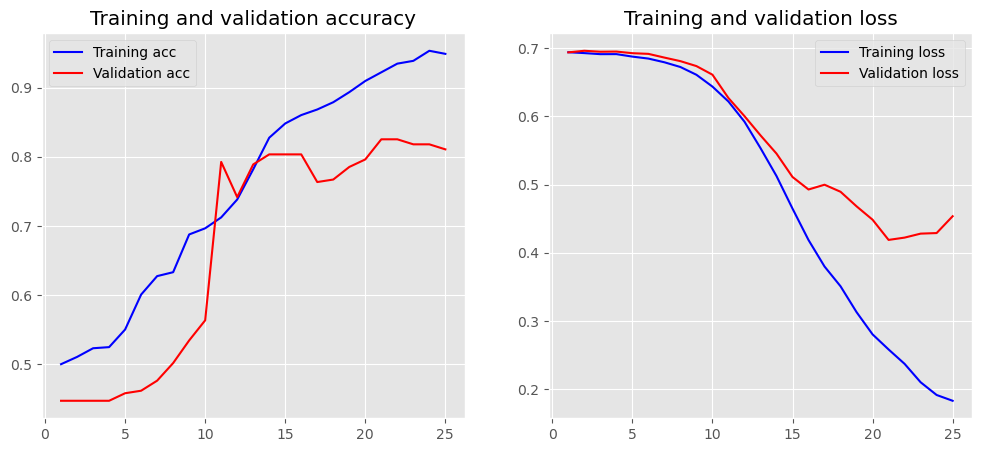

In [36]:
plot_history(history_emb2)